In [47]:
import sys
import os

# Ensure local packages (models, lib_QEC) are importable
for p in [os.path.abspath(".." ), os.path.abspath(".")]:
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Statevector, Operator
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import SuzukiTrotter
from qiskit_aer import AerSimulator

from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

import matplotlib.pyplot as plt

# for exact classical simulation
from scipy.linalg import expm
from scipy.integrate import solve_ivp

# Import Lipkin model functions
from models.Lipkin import diabolic_points, qpt_line, LipkinHamiltonian
from models.Lipkin_onehot import OptimizedLipkinSimulation
# from options_gen.lipkin_optimized_v4_gray import GrayCodeLipkin

In [48]:
# Simulate measurement noise on the energy basis projections
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer.noise import NoiseModel

# Get backend from real device (or fallback to local FakeAachen if offline/no credentials)
try:
    service = QiskitRuntimeService()
    backend = service.backend("ibm_aachen")
    print(f"Connected to IBM Quantum. Using backend: {backend.name}")
except Exception as e:
    from qiskit_ibm_runtime.fake_provider import FakeAachen
    backend = FakeAachen()
    print(f"IBM Quantum credentials not found ({e}). Falling back to local {backend.name}.")


Using noise model from: ibm_aachen


# Parameters

In [49]:
# Lipkin model parameters
N = 4 # system size

# Time evolution
x0, y0 = -0.5, 0.0 # initial point
xf, yf = -0.3, 1.5 # final point
T = 10.0         # final driving time
n_steps = 20       # steps in time
trotter_order = 2  # used in SuzukiTrotter decomposition on QC

# Circuit construction method
use_optimized_trotter = True  # True: use lipkin_optimized_v3.py (efficient XY gates)
                               # False: use default Qiskit PauliEvolutionGate

# Quantum Computer transpilation
qc_optimization_level = 3  # optimization level for transpilation on QC
approximation_degree = 1. # 1.0=no approximation, 0.0=maximal approximation

# Qiskit Estimator
number_of_shots = 4000
enable_dd = False             # Dynamical Decoupling (often False for dense circuits)
enable_twirling = True        # Pauli Twirling (good for error suppression)

# option to run on quantum backend
run_on_quantum_backend = True # just so we can run the full notebook at once for testing
rerun_continuous_simulation = True # just to make the execution faster


# Aer simulator
aer_optimization_level = qc_optimization_level  # keep the same as for QC transpilation
number_of_shots_aer = number_of_shots

## Path Definition in (x,y) Parameter Space

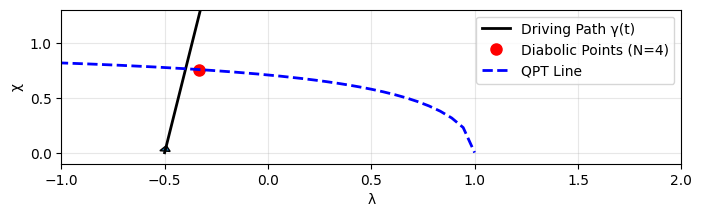

In [50]:
def gamma(t, T):
    """Define the driving path gamma(t) in (x,y) parameter space."""
    # Linear path from x0, y0 to xf, yf
    x = x0 + (xf - x0) * t / T
    y = y0 + (yf - y0) * t / T
    
    return x, y

ts = np.linspace(0, T, 100)
xs, ys = zip(*[gamma(t, T) for t in ts])

plt.figure(figsize=(8, 6))
# Plot driving path
plt.plot(xs, ys, 'k-', linewidth=2, label='Driving Path γ(t)')
plt.arrow(xs[0], ys[0], xs[1]-xs[0], ys[1]-ys[0], head_width=0.05, head_length=0.05)

# Plot diabolic points
dp = diabolic_points(N)
plt.plot(dp[:, 0], dp[:, 1], 'ro', markersize=8, label=f'Diabolic Points (N={N})')

# Plot QPT line
lambda_vals = np.linspace(-10, 0.999999, 200)
chi_vals = qpt_line(lambda_vals)
plt.plot(lambda_vals, chi_vals, 'b--', linewidth=2, label='QPT Line')
# set image resolution to 200x600
plt.gcf().set_size_inches(8, 2)
plt.xlabel('λ')
plt.ylabel('χ')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xlim(-1, 2)
plt.ylim(-0.1, 1.3)
plt.show()

## Hamiltonian definition

### Original N+1 dim implementation

In [51]:
dim_H = N + 1  # Number of physical states in the j=N/2 sector
num_qubits_orig = int(np.ceil(np.log2(dim_H)))

def lipkin_in_time(t: float, T: float, atol: float = 1e-10) -> SparsePauliOp:
    """Build Lipkin Hamiltonian as SparsePauliOp with proper padding to 2^n dimension."""
    x, y = gamma(t, T)
    H_physical = LipkinHamiltonian(N, λ=x, χ=y)
    
    # Pad to 2^n for quantum circuit compatibility
    dim = N + 1
    padded_dim = 2**num_qubits_orig
    H_padded = np.zeros((padded_dim, padded_dim), dtype=complex)
    H_padded[:dim, :dim] = H_physical
    
    # Add large energy offset to non-physical states
    # This keeps them out of the low-energy subspace
    E_max = np.max(np.diag(H_physical.real))  # Maximum physical energy
    offset = E_max + 1e10  # Large energy gap
    for i in range(dim, padded_dim):
        H_padded[i, i] = offset
    
    return SparsePauliOp.from_operator(Operator(H_padded)).simplify(atol=atol)

print(f'Lipkin model: N = {N}')
print(f'Hilbert space dimension (physical): {dim_H}')
print(f'Number of qubits: {num_qubits_orig}')
print(f'Padded dimension: {2**num_qubits_orig}')
print(f'Number of terms in Hamiltonian at t=0: {len(lipkin_in_time(0, T, atol=1e-10))}')

Lipkin model: N = 4
Hilbert space dimension (physical): 5
Number of qubits: 3
Padded dimension: 8
Number of terms in Hamiltonian at t=0: 16


### Lipkin one-hot mapping

In [52]:
dim_H = N + 1  # Number of physical states in the j=N/2 sector
sim = OptimizedLipkinSimulation(N)
# sim = GrayCodeLipkin(N)
num_qubits = sim.num_qubits # N+1 for one-hot encoding
print(f'Using {num_qubits} qubits for optimized encoding.')

Using 5 qubits for optimized encoding.


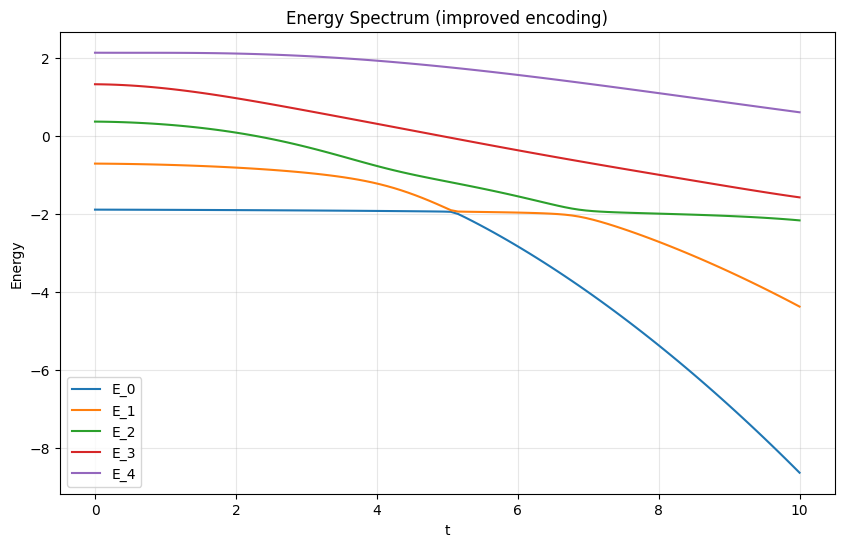

In [53]:
# Plot spectrum using OptimizedLipkinSimulation from lipkin_optimized_v3.py
n_points = 100
t_values = np.linspace(0, T, n_points)
eigenvalues_optimized = np.zeros((n_points, dim_H))
for i, t in enumerate(t_values):
    x, y = gamma(t, T)
    H_opt = sim.hamiltonian_matrix(x, y)
    evals_opt = np.linalg.eigvalsh(H_opt)
    eigenvalues_optimized[i, :] = evals_opt[:dim_H]

fig, ax = plt.subplots(figsize=(10, 6))
for j in range(dim_H):
    ax.plot(t_values, eigenvalues_optimized[:, j], label=f'E_{j}')

ax.set_xlabel('t')
ax.set_ylabel('Energy')
ax.set_title('Energy Spectrum (improved encoding)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

## Time evolution circuit

Uses statevector simulation to preserve full quantum information, then project onto energy eigenbasis.

- Usually we start from some easily preparable state, so the first step would be ommitted. Here the initial state is set to be the ground state of $H(0)$, so we have the freedom. But it is cheating.
- Classical diagonalization is also used at the final time, this could be replaced by quantum state tomography to do the computation fully on QC. However, practically computational basis is good enough for many practical applications, here we just want to intuitively understand the result. Or we would measure in the end some observable (like total magnetization).

At final time we have $|\psi\rangle = \sum_i c_i |E_i\rangle$ in the energy basis, for $c_i = \langle E_i|\psi\rangle$.

### Create the circuit with initial position and Trotterization

In [54]:
# Build the circuit using the selected method
qc = sim.build_adiabatic_circuit(gamma, T, n_steps, use_optimized=use_optimized_trotter, trotter_order=trotter_order)

print(f"Circuit summary:")
print(f"N: {N}")
print(f"Method: {'Optimized (efficient XY gates)' if use_optimized_trotter else 'Default Qiskit (PauliEvolutionGate) with SuzukiTrotter of order ' + str(trotter_order)}")
print(f"Number of qubits: {num_qubits}")
print(f"Depth: {qc.decompose().depth()}")
print(f"Gates: {qc.decompose().size()}")
# qc.decompose().decompose().draw('mpl', fold=-1)

Circuit summary:
N: 4
Method: Optimized (efficient XY gates)
Number of qubits: 5
Depth: 679
Gates: 2082


### Get the final Hamiltonian and its eigenbasis

In [55]:
xf, yf = gamma(T, T)
Hf_matrix = sim.hamiltonian_matrix(xf, yf)
evalsf, evecsf = np.linalg.eigh(Hf_matrix)

print(f"Physical eigenvalues at T={T}:")
for i, ev in enumerate(evalsf[:dim_H]):
    print(f"  E_{i} = {ev:.6f}")

Physical eigenvalues at T=10.0:
  E_0 = -8.631868
  E_1 = -4.371744
  E_2 = -2.161135
  E_3 = -1.571135
  E_4 = 0.610882


In [56]:
# Create projector observables using one-hot embedding
# In one-hot encoding, physical state |m⟩ corresponds to computational state with bit m set
# i.e., state |m⟩ → |0...010...0⟩ with 1 at position m (index 2^m in computational basis)

projectors = sim.energy_projectors(xf, yf)
print(f"Created {len(projectors)} projectors onto final energy eigenstates.")

Created 5 projectors onto final energy eigenstates.


## Transpile and run on backend

In [57]:
# Transpile circuit for the specific backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=3
                                   ,layout_method='sabre'  # 'trivial', 'dense', and 'sabre'
                                   ,routing_method='sabre' # 'basic', 'lookahead', 'sabre'
                                    ,translation_method='synthesis'
                                    ,approximation_degree=approximation_degree # 1.0=no approximation, 0.0=maximal approximation
                                  )
qc_transpiled = pm.run(qc)
print(f"Transpiled circuit: {qc_transpiled.size()} gates, depth {qc_transpiled.depth()}")
print(f"Transpiled circuit qubits: {qc_transpiled.num_qubits}")

# Map observables to the transpiled circuit's qubit layout
# The layout tells us which physical qubits our logical qubits were mapped to
layout = qc_transpiled.layout
projectors_mapped = [obs.apply_layout(layout, num_qubits=qc_transpiled.num_qubits) for obs in projectors]
print(f"Mapped observables to {qc_transpiled.num_qubits} qubits using circuit layout")

# qc_transpiled.decompose().draw('mpl', idle_wires=False)

Transpiled circuit: 3131 gates, depth 1263
Transpiled circuit qubits: 156
Mapped observables to 156 qubits using circuit layout


In [58]:
# Configure Estimator with Error Mitigation
estimator = Estimator(backend)

# Set resilience level for error mitigation
# Level 0: No mitigation
# Level 1: TREX (measurement error mitigation)
# Level 2: ZNE (zero-noise extrapolation) + TREX + twirling
resilience_level = 2 # does not influence the runtime
estimator.options.resilience_level = resilience_level  # type: ignore (because pylance marks this as error)

# Additional options for best results
estimator.options.dynamical_decoupling.enable = enable_dd  # type: ignore
estimator.options.dynamical_decoupling.sequence_type = "XY4"  # type: ignore
estimator.options.twirling.enable_gates = enable_twirling  # type: ignore
estimator.options.default_shots = number_of_shots  # type: ignore

<div class="alert alert-warning">
Run on quantum backend
</div>

In [59]:
# Run Estimator - one PUB with all observables (using mapped observables)
# Each projector ⟨ψ|E_k⟩⟨E_k|ψ⟩ = |⟨E_k|ψ⟩|² gives the probability
if run_on_quantum_backend:
    pub = (qc_transpiled, projectors_mapped)

    job = estimator.run([pub])
    print(f"Job submitted: {job.job_id()}")
    result = job.result()

    # Extract results
    pub_result = result[0]
    energy_probs_raw = pub_result.data.evs  # Expectation values = probabilities
    std_errors = pub_result.data.stds       # Standard errors

    print(f"\nRaw expectation values (probabilities):")
    for k, (ev, std) in enumerate(zip(energy_probs_raw, std_errors)):
        print(f"  P(E_{k}) = {ev:.4f} ± {std:.4f}")
else:
    print("Skipping quantum backend execution.")

Job submitted: d7b135ar4f1s73a1osng

Raw expectation values (probabilities):
  P(E_0) = 0.0291 ± 0.0410
  P(E_1) = 0.0685 ± 0.0330
  P(E_2) = 0.4165 ± 0.0375
  P(E_3) = 0.0581 ± 0.0359
  P(E_4) = 0.0654 ± 0.0277


In [60]:
# Process Estimator results: expectation values are the probabilities
# Clip to valid probability range (small negatives from noise)
if run_on_quantum_backend:
    energy_probs_quantum = np.clip(energy_probs_raw, 0, 1)

    # Normalize (should sum to ~1 for physical states)
    total_prob = np.sum(energy_probs_quantum)
    if total_prob > 0:
        energy_probs_quantum = energy_probs_quantum / total_prob

    print("Energy eigenstate populations (from Estimator with error mitigation):")
    for i, (prob, std) in enumerate(zip(energy_probs_quantum, std_errors)):
        print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f} ± {std:.4f}")

    # Expected energy
    expected_E = np.sum(evalsf[:dim_H] * energy_probs_quantum)
    ground_E = evalsf[0]
    print(f"\n⟨E⟩ = {expected_E:.4f}")
    print(f"E_0 = {ground_E:.4f}")
    print(f"Excitation: ⟨E⟩ - E_0 = {expected_E - ground_E:.4f}")
else:
    print("Skipping quantum backend execution.")

Energy eigenstate populations (from Estimator with error mitigation):
  E_0 (E=-8.6319): 0.0457 ± 0.0410
  E_1 (E=-4.3717): 0.1074 ± 0.0330
  E_2 (E=-2.1611): 0.6532 ± 0.0375
  E_3 (E=-1.5711): 0.0911 ± 0.0359
  E_4 (E=0.6109): 0.1026 ± 0.0277

⟨E⟩ = -2.3557
E_0 = -8.6319
Excitation: ⟨E⟩ - E_0 = 6.2762


### Aer Simulator (noiseless quantum simulation)

In [61]:
# Aer Simulator without noise - simulates the circuit with sampling (like real QC but no noise)
from qiskit_aer import AerSimulator
from qiskit import transpile

# Build the measurement circuit with energy basis rotation
# For one-hot encoding, we need to embed U_dagger into the full 2^(N+1) space
# The physical subspace is spanned by one-hot states |2^m⟩ for m = 0, ..., N

# Create the full unitary that acts on the one-hot subspace
full_dim = 2**num_qubits
one_hot_indices = [1 << m for m in range(dim_H)]  # [1, 2, 4, 8, ...] for one-hot states

# Build the transformation matrix in the full computational basis
U_dagger_full = np.eye(full_dim, dtype=complex)
for i, idx_i in enumerate(one_hot_indices):
    for j, idx_j in enumerate(one_hot_indices):
        U_dagger_full[idx_i, idx_j] = evecsf.conj().T[i, j]

# Check unitarity
is_unitary = np.allclose(U_dagger_full @ U_dagger_full.conj().T, np.eye(full_dim), atol=1e-10)
print(f"U_dagger_full is unitary: {is_unitary}")

# IMPORTANT: Decompose the circuit first to eliminate XXPlusYYGate before adding unitary
qc_decomposed = qc.decompose()

qc_aer = qc_decomposed.copy()
qc_aer.unitary(U_dagger_full, range(num_qubits), label='U†')
qc_aer.measure_all()

# Run on noiseless Aer simulator
aer_noiseless = AerSimulator(method='statevector', seed_simulator=42)

# Use optimization_level=0 to prevent further decomposition
qc_aer_transpiled = transpile(qc_aer, aer_noiseless, optimization_level=0)

job_aer = aer_noiseless.run(qc_aer_transpiled, shots=number_of_shots_aer)
counts_aer = job_aer.result().get_counts()

# Convert counts to probabilities - extract one-hot states
total_shots_aer = sum(counts_aer.values())
aer_probs = np.zeros(dim_H)
for m in range(dim_H):
    bitstring = format(one_hot_indices[m], f'0{num_qubits}b')
    aer_probs[m] = counts_aer.get(bitstring, 0) / total_shots_aer

# Normalize
aer_prob_sum = np.sum(aer_probs)
if aer_prob_sum > 0:
    aer_probs_normalized = aer_probs / aer_prob_sum
else:
    aer_probs_normalized = aer_probs

print(f"Aer Simulator (noiseless, {total_shots_aer} shots):")
for i, prob in enumerate(aer_probs_normalized):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

# Check leakage to non-physical states
leakage = 1.0 - sum(counts_aer.get(format(idx, f'0{num_qubits}b'), 0) for idx in one_hot_indices) / total_shots_aer
print(f"  Leakage to non-physical states: {leakage:.6f}")

U_dagger_full is unitary: True
Aer Simulator (noiseless, 4000 shots):
  E_0 (E=-8.6319): 0.0357
  E_1 (E=-4.3717): 0.0955
  E_2 (E=-2.1611): 0.7810
  E_3 (E=-1.5711): 0.0628
  E_4 (E=0.6109): 0.0250
  Leakage to non-physical states: 0.000000


### Aer Simulator with device noise model

In [62]:
# Aer Simulator WITH noise from the real device
from qiskit_aer import AerSimulator
from qiskit import transpile

# Build the measurement circuit with energy basis rotation (same as noiseless)
qc_aer_noisy = qc.copy()
qc_aer_noisy.unitary(U_dagger_full, range(num_qubits), label='U†')
qc_aer_noisy.measure_all()

# Run on Aer simulator with noise model from the real backend
# Use trivial layout to keep logical-to-physical qubit mapping aligned with one_hot_indices
aer_noisy = AerSimulator.from_backend(backend)
qc_aer_noisy_transpiled = transpile(
    qc_aer_noisy,
    aer_noisy,
    optimization_level=3,
    layout_method="trivial",
)
job_aer_noisy = aer_noisy.run(qc_aer_noisy_transpiled, shots=10000)
counts_aer_noisy = job_aer_noisy.result().get_counts()

# Convert counts to probabilities - extract one-hot states
total_shots_aer_noisy = sum(counts_aer_noisy.values())
aer_noisy_probs = np.zeros(dim_H)
for m in range(dim_H):
    bitstring = format(one_hot_indices[m], f'0{num_qubits}b')
    aer_noisy_probs[m] = counts_aer_noisy.get(bitstring, 0) / total_shots_aer_noisy

# Normalize
aer_noisy_prob_sum = np.sum(aer_noisy_probs)
if aer_noisy_prob_sum > 0:
    aer_noisy_probs_normalized = aer_noisy_probs / aer_noisy_prob_sum
else:
    aer_noisy_probs_normalized = aer_noisy_probs

print(f"Aer Simulator (with {backend.name} noise, {total_shots_aer_noisy} shots):")
for i, prob in enumerate(aer_noisy_probs_normalized):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

# Check leakage to non-physical states
leakage_noisy = 1.0 - sum(counts_aer_noisy.get(format(idx, f'0{num_qubits}b'), 0) for idx in one_hot_indices) / total_shots_aer_noisy
print(f"  Leakage to non-physical states: {leakage_noisy:.6f}")

Aer Simulator (with ibm_aachen noise, 10000 shots):
  E_0 (E=-8.6319): 0.1635
  E_1 (E=-4.3717): 0.1859
  E_2 (E=-2.1611): 0.3169
  E_3 (E=-1.5711): 0.1716
  E_4 (E=0.6109): 0.1620
  Leakage to non-physical states: 0.790800


### Classical simulation of discretized evolution
Does not suffer from Trotterization error, since each step is performed using exact $U(dt)$ step (number of steps is the same `n_steps`) which uses constant Hamiltonian at midpoint of that time step.

In [63]:
# Classical piecewise-constant simulation (exact exp(-iH dt) at each interval)
# 
# This simulates "ideal Trotterization" where each time step uses the exact
# matrix exponential exp(-i H(t_mid) dt), but the Hamiltonian is treated as
# constant during each interval. No Trotter decomposition error, but still
# has discretization error from piecewise-constant approximation.

# Get initial ground state in physical space
x0_init, y0_init = gamma(0.0, T)
H0_physical = sim.hamiltonian_matrix(x0_init, y0_init)
_, evecs0_physical = np.linalg.eigh(H0_physical)
psi_piecewise = evecs0_physical[:, 0].copy()

dt = T / n_steps

# Evolve using piecewise-constant Hamiltonians (exact exp at each step)
for step in range(n_steps):
    # Evaluate Hamiltonian at midpoint of interval (same as Trotter circuit)
    t_mid = (step + 0.5) * dt
    lam_t, chi_t = gamma(t_mid, T)
    H_t = sim.hamiltonian_matrix(lam_t, chi_t)
    
    # Exact unitary evolution for this step
    U_step = expm(-1j * H_t * dt)
    psi_piecewise = U_step @ psi_piecewise

# Project onto energy eigenbasis of H(T)
piecewise_energy_amps = evecsf.conj().T @ psi_piecewise
piecewise_probs = np.abs(piecewise_energy_amps)**2

print(f"Classical piecewise-constant simulation (exact exp(-iH dt) per step):")
print(f"  n_steps={n_steps}, dt={dt:.4f}")
for i, prob in enumerate(piecewise_probs):
    print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

Classical piecewise-constant simulation (exact exp(-iH dt) per step):
  n_steps=20, dt=0.5000
  E_0 (E=-8.6319): 0.0045
  E_1 (E=-4.3717): 0.0853
  E_2 (E=-2.1611): 0.8165
  E_3 (E=-1.5711): 0.0936
  E_4 (E=0.6109): 0.0001


### Exact classical simulation (high precision using solve_ivp)

In [64]:
# Exact classical simulation (high precision using solve_ivp)
# This works directly in the physical (N+1)-dimensional Hilbert space.
if rerun_continuous_simulation:
    def classical_continuous_onehot(T, psi0):
        """Solve Schrödinger equation continuously using adaptive RK45 in physical space."""
        def rhs(t, psi_real_imag):
            # Split real and imaginary parts for real-valued ODE solver
            n = len(psi_real_imag) // 2
            psi = psi_real_imag[:n] + 1j * psi_real_imag[n:]
            x, y = gamma(t, T)
            H = sim.hamiltonian_matrix(x, y)  # Physical (N+1) x (N+1) Hamiltonian
            dpsi = -1j * H @ psi
            return np.concatenate([dpsi.real, dpsi.imag])
        
        # Initial condition: split into real and imaginary parts
        y0 = np.concatenate([psi0.real, psi0.imag])
        
        sol = solve_ivp(rhs, (0, T), y0, method='RK45', rtol=1e-10, atol=1e-12)
        
        # Reconstruct complex state
        n = len(psi0)
        psi_final = sol.y[:n, -1] + 1j * sol.y[n:, -1]
        return psi_final

    # Get initial ground state in physical space
    x0_init, y0_init = gamma(0.0, T)
    H0_physical = sim.hamiltonian_matrix(x0_init, y0_init)
    _, evecs0_physical = np.linalg.eigh(H0_physical)

    psi_precise = classical_continuous_onehot(T, evecs0_physical[:, 0])

    # Project onto energy eigenbasis of H(T)
    energy_amplitudes_precise = evecsf.conj().T @ psi_precise
    classical_probs_precise = np.abs(energy_amplitudes_precise)**2

    print(f"Exact classical simulation (RK45, high precision):")
    print(f"  This is the CORRECT solution of the Schrödinger equation")
    for i, prob in enumerate(classical_probs_precise):
        print(f"  E_{i} (E={evalsf[i]:.4f}): {prob:.4f}")

Exact classical simulation (RK45, high precision):
  This is the CORRECT solution of the Schrödinger equation
  E_0 (E=-8.6319): 0.0043
  E_1 (E=-4.3717): 0.0861
  E_2 (E=-2.1611): 0.8136
  E_3 (E=-1.5711): 0.0959
  E_4 (E=0.6109): 0.0001


# Final comparison

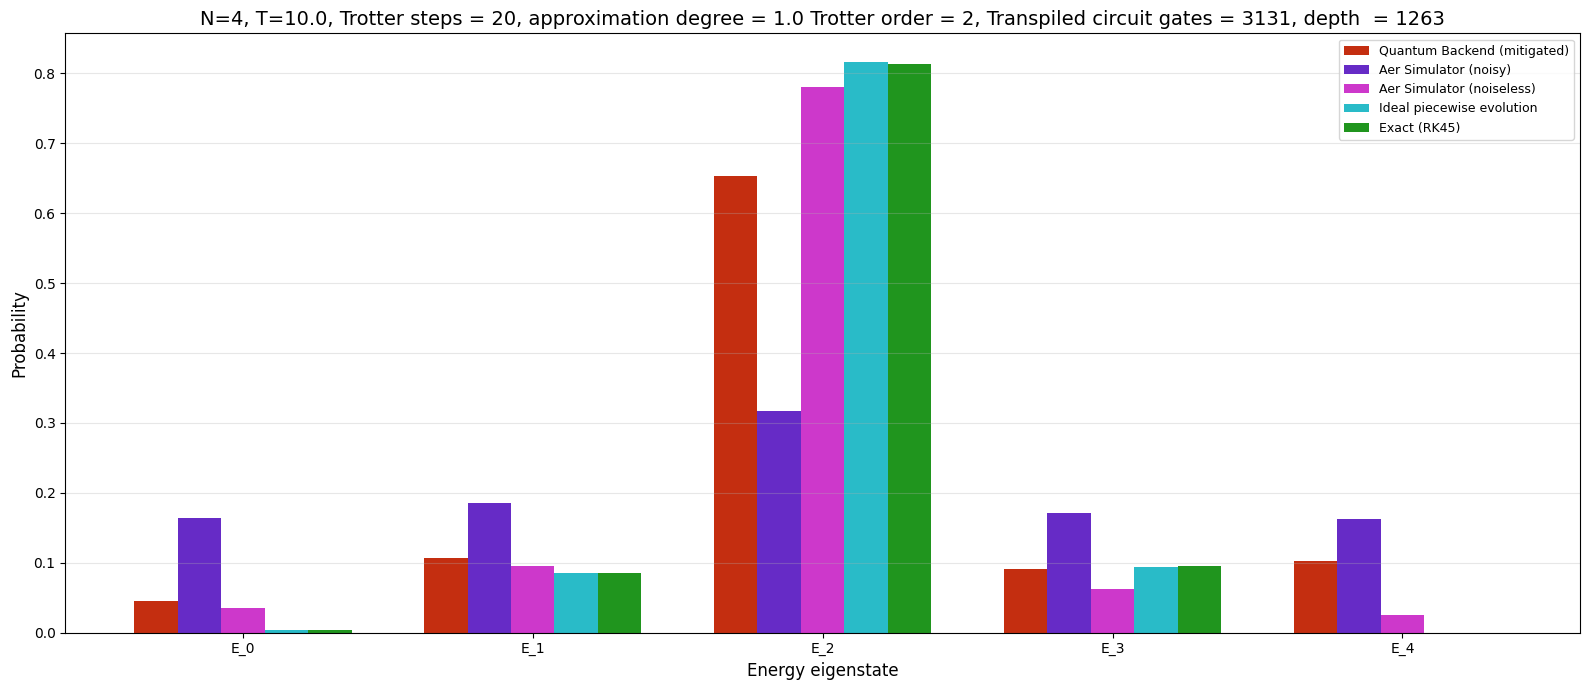

In [65]:
# Comparison plot: Real Hardware vs Aer (noisy) vs Aer (noiseless) vs Trotter (ideal) vs Precise
fig, ax = plt.subplots(figsize=(16, 7))

x_pos = np.arange(dim_H)
width = 0.15

if run_on_quantum_backend:
    ax.bar(x_pos - 2*width, energy_probs_quantum, width, label='Quantum Backend (mitigated)', color="#c42e10")
ax.bar(x_pos - 1*width, aer_noisy_probs_normalized, width, label='Aer Simulator (noisy)', color="#662bc6")
ax.bar(x_pos, aer_probs_normalized, width, label='Aer Simulator (noiseless)', color="#cd38cb")
ax.bar(x_pos + 1*width, piecewise_probs, width, label='Ideal piecewise evolution', color="#29bbc8")
ax.bar(x_pos + 2*width, classical_probs_precise, width, label='Exact (RK45)', color="#20951e")

ax.set_xlabel("Energy eigenstate", fontsize=12)
ax.set_ylabel("Probability", fontsize=12)
ax.set_title(f"N={N}, T={T}, Trotter steps = {n_steps}, approximation degree = {approximation_degree} Trotter order = {trotter_order}, Transpiled circuit gates = {qc_transpiled.size()}, depth  = {qc_transpiled.depth()}", fontsize=14)
ax.set_xticks(x_pos)
ax.set_xticklabels([f'E_{i}' for i in range(dim_H)])
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [66]:
# Detailed final summary with all results for debugging
print("=" * 80)
print("DETAILED SIMULATION SUMMARY")
print("=" * 80)

print("\n### SIMULATION PARAMETERS ###")
print(f"  N (system size): {N}")
print(f"  Hilbert space dimension: {dim_H}")
print(f"  Number of qubits: {num_qubits}")
print(f"  Total evolution time T: {T}")
print(f"  Number of Trotter steps: {n_steps}")
print(f"  dt = T/n_steps: {T/n_steps:.4f}")
print(f"  Trotter order: {trotter_order}")
print(f"  Use optimized Trotter: {use_optimized_trotter}")
print(f"  Path: ({x0}, {y0}) -> ({xf}, {yf})")

print("\n### CIRCUIT DETAILS ###")
print(f"  Original circuit depth: {qc.decompose().depth()}")
print(f"  Original circuit gates: {qc.decompose().size()}")
print(f"  Transpiled circuit depth: {qc_transpiled.depth()}")
print(f"  Transpiled circuit gates: {qc_transpiled.size()}")
print(f"  Transpiled circuit qubits: {qc_transpiled.num_qubits}")
print(f"  Optimization level: {qc_optimization_level}")
print(f"  Approximation degree: {approximation_degree}")

print("\n### BACKEND & ESTIMATOR CONFIG ###")
print(f"  Backend: {backend.name}")
print(f"  Number of shots: {number_of_shots}")
print(f"  Dynamical decoupling: {enable_dd}")
print(f"  Twirling: {enable_twirling}")

print("\n### FINAL HAMILTONIAN EIGENVALUES ###")
for i, ev in enumerate(evalsf[:dim_H]):
    print(f"  E_{i} = {ev:.6f}")

print("\n### ENERGY EIGENVECTORS (columns) ###")
print(evecsf)

print("\n### PROBABILITY DISTRIBUTIONS ###")
print(f"\n{'Method':<45} | " + " | ".join([f"P(E_{i})" for i in range(dim_H)]) + " | Sum")
print("-" * (45 + 12 * dim_H + 10))

# Aer noiseless
row = f"{'Aer Simulator (noiseless)':<45} | "
row += " | ".join([f"{p:.4f}" for p in aer_probs_normalized])
row += f" | {np.sum(aer_probs_normalized):.4f}"
print(row)

# Aer noisy
row = f"{'Aer Simulator (noisy)':<45} | "
row += " | ".join([f"{p:.4f}" for p in aer_noisy_probs_normalized])
row += f" | {np.sum(aer_noisy_probs_normalized):.4f}"
print(row)

# Piecewise constant
row = f"{'Discretized evolution (no Trotterization)':<45} | "
row += " | ".join([f"{p:.4f}" for p in piecewise_probs])
row += f" | {np.sum(piecewise_probs):.4f}"
print(row)

# Exact classical
row = f"{'Exact classical (RK45)':<45} | "
row += " | ".join([f"{p:.4f}" for p in classical_probs_precise])
row += f" | {np.sum(classical_probs_precise):.4f}"
print(row)

print("\n### EXPECTED ENERGIES ###")
E_aer_noiseless = np.sum(evalsf[:dim_H] * aer_probs_normalized)
E_aer_noisy = np.sum(evalsf[:dim_H] * aer_noisy_probs_normalized)
E_piecewise = np.sum(evalsf[:dim_H] * piecewise_probs)
E_exact = np.sum(evalsf[:dim_H] * classical_probs_precise)
print(f"  Ground state energy E_0: {evalsf[0]:.6f}")
print(f"  Aer noiseless <E>: {E_aer_noiseless:.6f} (excitation: {E_aer_noiseless - evalsf[0]:.6f})")
print(f"  Aer noisy <E>: {E_aer_noisy:.6f} (excitation: {E_aer_noisy - evalsf[0]:.6f})")
print(f"  Piecewise <E>: {E_piecewise:.6f} (excitation: {E_piecewise - evalsf[0]:.6f})")
print(f"  Exact <E>: {E_exact:.6f} (excitation: {E_exact - evalsf[0]:.6f})")

print("\n### LEAKAGE TO NON-PHYSICAL STATES ###")
print(f"  Aer noiseless leakage: {leakage:.6f}")
print(f"  Aer noisy leakage: {leakage_noisy:.6f}")

print("\n### FIDELITY WITH EXACT SOLUTION ###")
fidelity_aer = np.sum(np.sqrt(aer_probs_normalized * classical_probs_precise))**2
fidelity_noisy = np.sum(np.sqrt(aer_noisy_probs_normalized * classical_probs_precise))**2
fidelity_piecewise = np.sum(np.sqrt(piecewise_probs * classical_probs_precise))**2
print(f"  Aer noiseless vs Exact: {fidelity_aer:.6f}")
print(f"  Aer noisy vs Exact: {fidelity_noisy:.6f}")
print(f"  Piecewise vs Exact: {fidelity_piecewise:.6f}")

print("\n### FINAL STATE AMPLITUDES (exact classical) ###")
for i, amp in enumerate(energy_amplitudes_precise):
    print(f"  c_{i} = {amp:.6f} (|c_{i}|² = {np.abs(amp)**2:.6f})")

print("\n" + "=" * 80)

DETAILED SIMULATION SUMMARY

### SIMULATION PARAMETERS ###
  N (system size): 4
  Hilbert space dimension: 5
  Number of qubits: 5
  Total evolution time T: 10.0
  Number of Trotter steps: 20
  dt = T/n_steps: 0.5000
  Trotter order: 2
  Use optimized Trotter: True
  Path: (-0.5, 0.0) -> (-0.3, 1.5)

### CIRCUIT DETAILS ###
  Original circuit depth: 679
  Original circuit gates: 2082
  Transpiled circuit depth: 1263
  Transpiled circuit gates: 3131
  Transpiled circuit qubits: 156
  Optimization level: 3
  Approximation degree: 1.0

### BACKEND & ESTIMATOR CONFIG ###
  Backend: ibm_aachen
  Number of shots: 4000
  Dynamical decoupling: False
  Twirling: True

### FINAL HAMILTONIAN EIGENVALUES ###
  E_0 = -8.631868
  E_1 = -4.371744
  E_2 = -2.161135
  E_3 = -1.571135
  E_4 = 0.610882

### ENERGY EIGENVECTORS (columns) ###
[[-0.82116551 -0.47908283  0.14896615 -0.21219583 -0.17014365]
 [-0.54031392  0.48935542 -0.26840901  0.42529438  0.46440653]
 [-0.18184062  0.66775265  0.05531406 -0

In [67]:
``

SyntaxError: invalid syntax (1016415176.py, line 1)